In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving features.csv to features.csv
Saving stores.csv to stores.csv
Saving train.csv to train.csv


In [ ]:
train = pd.read_csv('train.csv')
features = pd.read_csv('features.csv')
stores = pd.read_csv('stores.csv')

In [ ]:

print("train:", train.shape)


train: (421570, 5)


In [ ]:

print("features:", features.shape)


features: (8190, 12)


In [ ]:

print("stores:", stores.shape)

stores: (45, 3)


In [ ]:
print("TRAIN COLUMNS:")
print(train.columns)

print("\nFEATURES COLUMNS:")
print(features.columns)

print("\nSTORES COLUMNS:")
print(stores.columns)

TRAIN COLUMNS:
Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday'], dtype='object')

FEATURES COLUMNS:
Index(['Store', 'Date', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2',
       'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment',
       'IsHoliday'],
      dtype='object')

STORES COLUMNS:
Index(['Store', 'Type', 'Size'], dtype='object')


In [ ]:
print("TRAIN MISSING:")
print(train.isnull().sum())

print("\nFEATURES MISSING:")
print(features.isnull().sum())

print("\nSTORES MISSING:")
print(stores.isnull().sum())

TRAIN MISSING:
Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

FEATURES MISSING:
Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64

STORES MISSING:
Store    0
Type     0
Size     0
dtype: int64


In [ ]:
train.info()
print("\n")
features.info()
print("\n")
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         8190 non-null   int64  
 1   Date          8190 non-null   object 
 2   Temperature   8190 non-null   float64
 3   Fuel_Price    8190 non-null   float64
 4   MarkDown1     4032 non-null   float64
 5   MarkDown2     2921 non-null   float64
 6   MarkDown3     3613 non-null   float64
 7   MarkDown4

In [ ]:
print("TRAIN DUPLICATES:", train.duplicated().sum())
print("FEATURES DUPLICATES:", features.duplicated().sum())
print("STORES DUPLICATES:", stores.duplicated().sum())

TRAIN DUPLICATES: 0
FEATURES DUPLICATES: 0
STORES DUPLICATES: 0


In [ ]:
print("MIN SALES:", train['Weekly_Sales'].min())
print("MAX SALES:", train['Weekly_Sales'].max())

MIN SALES: -4988.94
MAX SALES: 693099.36


In [ ]:
train = train[train['Weekly_Sales'] >= 0]
print("New shape:", train.shape)

New shape: (420285, 5)


In [ ]:
train['Date'] = pd.to_datetime(train['Date'])
features['Date'] = pd.to_datetime(features['Date'])

In [ ]:
print(train.dtypes)
print("\n")
print(features.dtypes)

Store                    int64
Dept                     int64
Date            datetime64[ns]
Weekly_Sales           float64
IsHoliday                 bool
dtype: object


Store                    int64
Date            datetime64[ns]
Temperature            float64
Fuel_Price             float64
MarkDown1              float64
MarkDown2              float64
MarkDown3              float64
MarkDown4              float64
MarkDown5              float64
CPI                    float64
Unemployment           float64
IsHoliday                 bool
dtype: object


In [ ]:
df = pd.merge(train, features, on=['Store', 'Date'], how='left')
df = pd.merge(df, stores, on='Store', how='left')

print(df.shape)
df.head()

(420285, 17)


,Store,Dept,Date,Weekly_Sales,IsHoliday_x,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


In [ ]:
# 1) Fix IsHoliday
df = df.drop(columns=['IsHoliday_y'])
df = df.rename(columns={'IsHoliday_x': 'IsHoliday'})

# 2) Drop MarkDown columns
df = df.drop(columns=['MarkDown1','MarkDown2','MarkDown3','MarkDown4','MarkDown5'])

print(df.shape)
df.head()

(420285, 11)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,211.350143,8.106,A,151315


In [ ]:
print(df.isnull().sum())

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
Type            0
Size            0
dtype: int64


In [ ]:
df['Weekly_Sales'].describe()

,Weekly_Sales
count,420285.000000
mean,16030.329773
std,22728.500149
min,0.000000
25%,2117.560000
50%,7659.090000
75%,20268.380000
max,693099.360000


In [ ]:
print(df['Date'].min())
print(df['Date'].max())

2010-02-05 00:00:00
2012-10-26 00:00:00


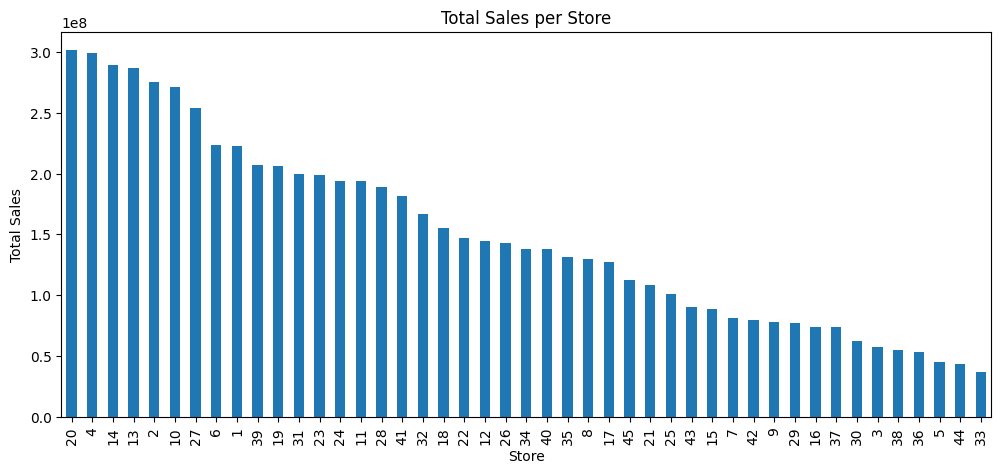

In [ ]:
store_sales = df.groupby('Store')['Weekly_Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(12,5))
store_sales.plot(kind='bar')
plt.title("Total Sales per Store")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.show()

In [ ]:
#This graph shows the total sales aggregated for each store.
# There is a significant variation in sales across stores, with some stores generating substantially higher revenue than others.
# This indicates differences in store performance, which may be influenced by store characteristics such as size or type. Understanding these differences is important for identifying high-performing and underperforming stores.

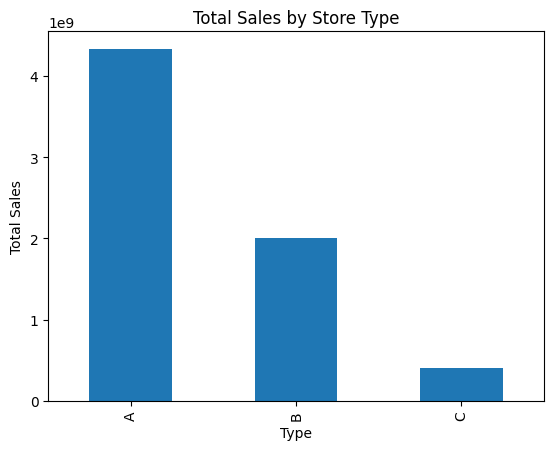

In [ ]:
type_sales = df.groupby('Type')['Weekly_Sales'].sum()

type_sales.plot(kind='bar')
plt.title("Total Sales by Store Type")
plt.xlabel("Type")
plt.ylabel("Total Sales")
plt.show()

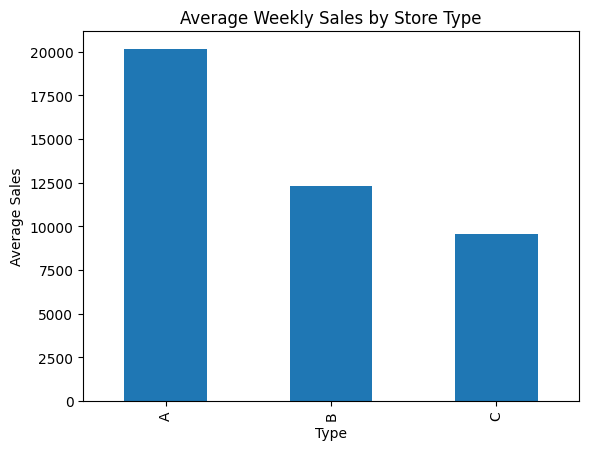

In [ ]:
avg_type_sales = df.groupby('Type')['Weekly_Sales'].mean()

avg_type_sales.plot(kind='bar')
plt.title("Average Weekly Sales by Store Type")
plt.xlabel("Type")
plt.ylabel("Average Sales")
plt.show()

In [ ]:
#This graph shows the average weekly sales for each store type. Type A stores have the highest average sales, followed by Type B and Type C.
#This suggests that store type is strongly associated with sales performance. The difference remains even after averaging, indicating that the variation is not due to the number of stores but reflects actual performance differences between store categories.

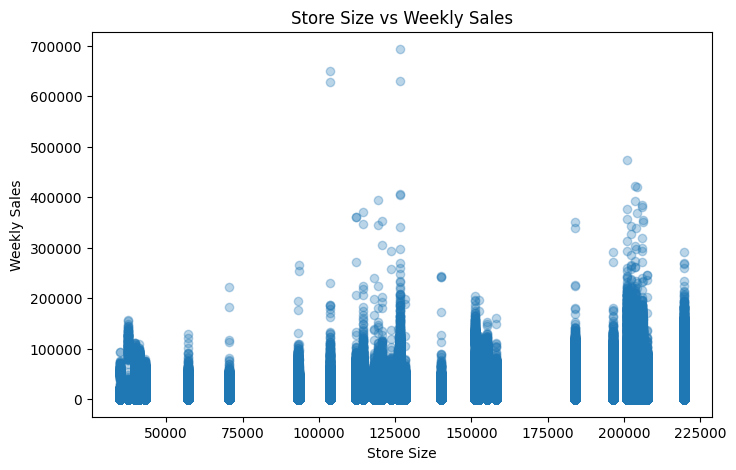

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df['Size'], df['Weekly_Sales'], alpha=0.3)
plt.title("Store Size vs Weekly Sales")
plt.xlabel("Store Size")
plt.ylabel("Weekly Sales")
plt.show()

In [ ]:
# This scatter plot illustrates the relationship between store size and weekly sales. Larger stores tend to achieve higher sales values, although there is considerable variability.
# This indicates that while store size influences sales performance, it is not the only determining factor, and other variables such as department or timing also play a role.

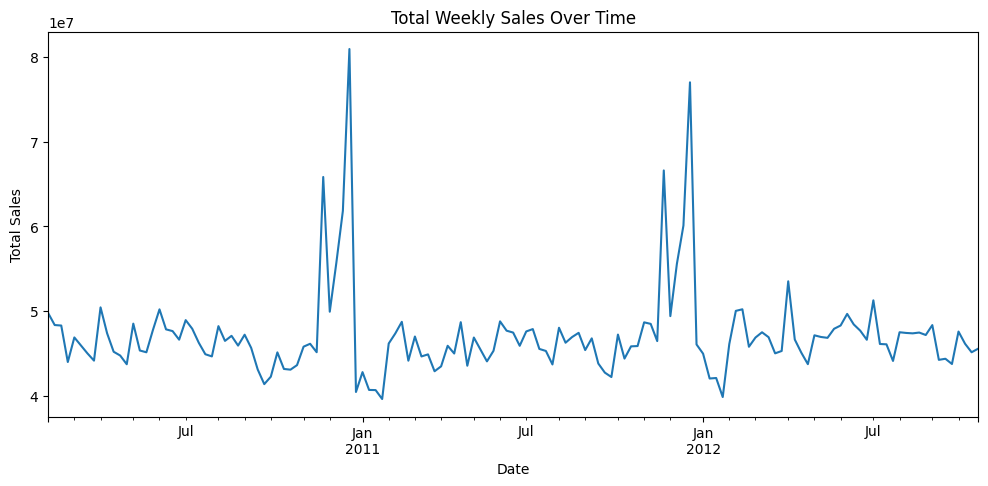

In [ ]:
weekly_trend = df.groupby('Date')['Weekly_Sales'].sum()

plt.figure(figsize=(12,5))
weekly_trend.plot()
plt.title("Total Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.show()

In [ ]:
# This graph shows total weekly sales over time.
# Sales remain relatively stable across most weeks but exhibit sharp spikes during specific periods, particularly toward the end of each year.
# These spikes suggest strong seasonal effects, likely driven by holiday demand. This highlights the importance of time-based patterns in retail sales analysis.

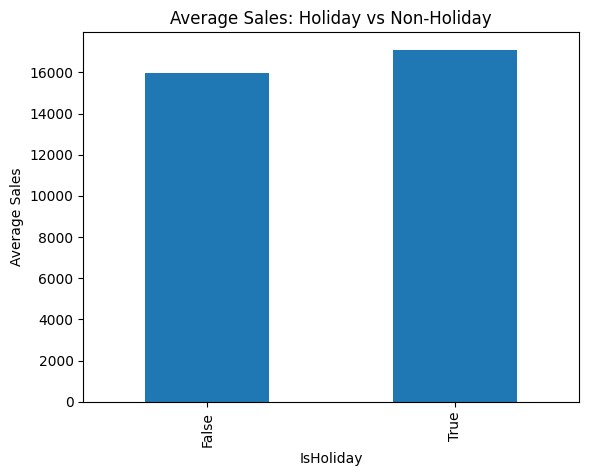

In [ ]:
holiday_sales = df.groupby('IsHoliday')['Weekly_Sales'].mean()

holiday_sales.plot(kind='bar')
plt.title("Average Sales: Holiday vs Non-Holiday")
plt.xlabel("IsHoliday")
plt.ylabel("Average Sales")
plt.show()

In [ ]:
#This graph compares average sales during holiday and non-holiday periods. While holiday weeks show slightly higher average sales, the difference is moderate.
# This is because holiday periods are relatively rare, and their impact appears as sharp spikes rather than consistent increases. Therefore, holidays influence sales significantly in specific periods rather than across the entire dataset.

In [ ]:
df['IsHoliday'].value_counts()

,count
IsHoliday,
False,390722
True,29563


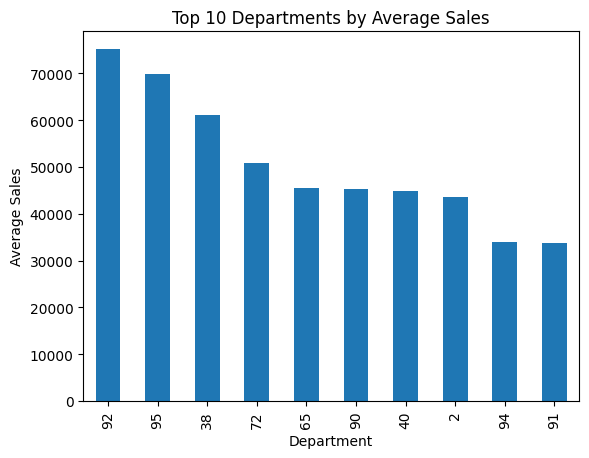

In [ ]:
dept_sales = df.groupby('Dept')['Weekly_Sales'].mean().sort_values(ascending=False).head(10)

dept_sales.plot(kind='bar')
plt.title("Top 10 Departments by Average Sales")
plt.xlabel("Department")
plt.ylabel("Average Sales")
plt.show()

In [ ]:
# This graph displays the top departments based on average weekly sales.
# There is a clear variation across departments, with some generating significantly higher revenue than others.
# This indicates that the type of products sold plays a major role in determining sales performance, and not all departments contribute equally to overall revenue.

In [ ]:
dept_holiday = df.groupby(['Dept', 'IsHoliday'])['Weekly_Sales'].mean().unstack()

dept_holiday.head(10)

IsHoliday,False,True
Dept,,
1,19176.542652,19704.819489
2,43712.565666,42203.264267
3,11764.630795,12180.299200
4,25921.624830,26679.602156
5,20538.617153,32460.097149
6,4528.782151,7851.197601
7,23702.744635,30259.191356
8,30244.564443,29482.361200
9,20311.033647,18986.211822


In [ ]:
# This table compares average sales for each department during holiday and non-holiday periods.
# Some departments show significant increases during holidays, while others remain stable.
# This indicates that holiday effects are not uniform across all departments and that certain product categories are more sensitive to seasonal demand.

In [ ]:
df.to_csv('cleaned_retail_data.csv', index=False)

In [ ]:
from google.colab import files
files.download('cleaned_retail_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
df = pd.read_csv('cleaned_retail_data.csv')

In [8]:
df.head()


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,211.350143,8.106,A,151315


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420285 entries, 0 to 420284
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         420285 non-null  int64  
 1   Dept          420285 non-null  int64  
 2   Date          420285 non-null  object 
 3   Weekly_Sales  420285 non-null  float64
 4   IsHoliday     420285 non-null  bool   
 5   Temperature   420285 non-null  float64
 6   Fuel_Price    420285 non-null  float64
 7   CPI           420285 non-null  float64
 8   Unemployment  420285 non-null  float64
 9   Type          420285 non-null  object 
 10  Size          420285 non-null  int64  
dtypes: bool(1), float64(5), int64(3), object(2)
memory usage: 32.5+ MB


In [ ]:
# Machine Learning Model

In [10]:
from sklearn.metrics import mean_absolute_error

# Baseline: predict average sales
baseline_value = df['Weekly_Sales'].mean()

baseline_predictions = [baseline_value] * len(df)

baseline_mae = mean_absolute_error(df['Weekly_Sales'], baseline_predictions)

print("Baseline prediction:", baseline_value)
print("Baseline MAE:", baseline_mae)

Baseline prediction: 16030.329773058756
Baseline MAE: 15177.283092117861


In [11]:
df = pd.get_dummies(df, columns=['Type'], drop_first=True)

In [12]:
features = ['Store', 'Dept', 'IsHoliday', 'Size', 'Type_B', 'Type_C']
X = df[features]
y = df['Weekly_Sales']

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [15]:
model_mae = mean_absolute_error(y_test, y_pred)

print("Model MAE:", model_mae)

Model MAE: 14614.447108543185


In [16]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)

Random Forest MAE: 2713.099422787748


In [17]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
print("RMSE:", rmse)

RMSE: 7349.398761689806


In [19]:
print("Baseline MAE:", baseline_mae)
print("Linear Regression MAE:", model_mae)
print("Random Forest MAE:", rf_mae)

Baseline MAE: 15177.283092117861
Linear Regression MAE: 14614.447108543185
Random Forest MAE: 2713.099422787748


In [20]:
import joblib

joblib.dump(rf, 'sales_model.pkl')
joblib.dump(features, 'model_features.pkl')

print("Model saved as sales_model.pkl")
print("Features saved as model_features.pkl")

Model saved as sales_model.pkl
Features saved as model_features.pkl


In [21]:
from google.colab import files

files.download('sales_model.pkl')
files.download('model_features.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# Extended feature model

extended_features = [
    'Store', 'Dept', 'IsHoliday', 'Size',
    'Type_B', 'Type_C',
    'Temperature', 'Fuel_Price', 'CPI', 'Unemployment'
]

X_ext = df[extended_features]
y = df['Weekly_Sales']

X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X_ext, y, test_size=0.2, random_state=42
)

rf_ext = RandomForestRegressor(n_estimators=50, random_state=42)
rf_ext.fit(X_train_ext, y_train_ext)

rf_ext_pred = rf_ext.predict(X_test_ext)

rf_ext_mae = mean_absolute_error(y_test_ext, rf_ext_pred)
rf_ext_rmse = np.sqrt(mean_squared_error(y_test_ext, rf_ext_pred))

print("Original RF MAE:", rf_mae)
print("Extended RF MAE:", rf_ext_mae)
print("Extended RF RMSE:", rf_ext_rmse)

Original RF MAE: 2713.099422787748
Extended RF MAE: 1914.5209765849363
Extended RF RMSE: 5483.603255266457


In [38]:
import joblib

joblib.dump(rf_ext, 'sales_model.pkl')
joblib.dump(extended_features, 'model_features.pkl')

print("Saved extended model")

Saved extended model


In [40]:
from google.colab import files

files.download('sales_model.pkl')
files.download('model_features.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

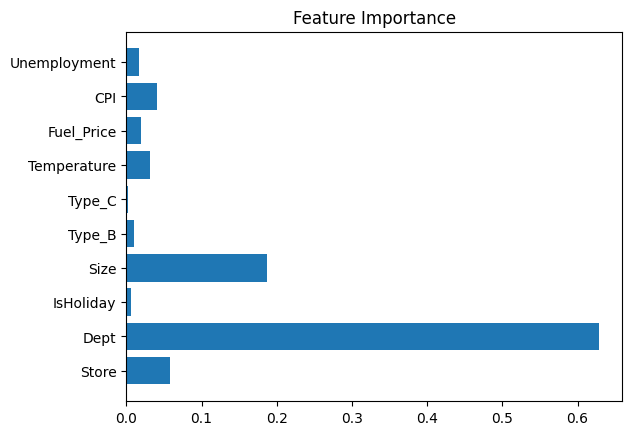

In [43]:
import matplotlib.pyplot as plt

importances = rf_ext.feature_importances_
feature_names = extended_features

plt.barh(feature_names, importances)
plt.title("Feature Importance")
plt.show()